In [1]:
!pip install -q tensorflow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
URL = "https://github.com/ywchiu/rcookbook/raw/master/chapter7/superstore_sales.csv"

raw = pd.read_csv(URL)
print("Shape ban đầu:", raw.shape)
display(raw.head())

# Chuẩn hóa tên cột
raw.columns = [c.strip() for c in raw.columns]
raw["Order Date"] = pd.to_datetime(raw["Order Date"])
raw["Sales"] = pd.to_numeric(raw["Sales"], errors="coerce")
raw = raw.dropna(subset=["Order Date", "Sales"])

# Tổng hợp doanh thu theo ngày
daily = (
    raw.groupby("Order Date", as_index=False)["Sales"]
       .sum()
       .rename(columns={"Order Date": "Date", "Sales": "Sales"})
       .sort_values("Date")
       .reset_index(drop=True)
)

print("Số ngày có giao dịch:", len(daily))
print("Khoảng thời gian:", daily["Date"].min(), "→", daily["Date"].max())
display(daily.head())

Shape ban đầu: (8399, 9)


,Order ID,Order Date,Order Quantity,Sales,Profit,Unit Price,Province,Customer Segment,Product Category
0,3,2010/10/13,6,261.5400,-213.25,38.94,Nunavut,Small Business,Office Supplies
1,293,2012/10/1,49,10123.0200,457.81,208.16,Nunavut,Consumer,Office Supplies
2,293,2012/10/1,27,244.5700,46.71,8.69,Nunavut,Consumer,Office Supplies
3,483,2011/7/10,30,4965.7595,1198.97,195.99,Nunavut,Corporate,Technology
4,515,2010/8/28,19,394.2700,30.94,21.78,Nunavut,Consumer,Office Supplies


Số ngày có giao dịch: 1418
Khoảng thời gian: 2009-01-01 00:00:00 → 2012-12-30 00:00:00


,Date,Sales
0,2009-01-01,1052.8400
1,2009-01-02,11101.8700
2,2009-01-03,31997.8555
3,2009-01-04,1254.2500
4,2009-01-05,39734.4040


In [3]:
daily["Year"]      = daily["Date"].dt.year
daily["Month"]     = daily["Date"].dt.month
daily["Day"]       = daily["Date"].dt.day
daily["DayOfWeek"] = daily["Date"].dt.dayofweek

# Chu kỳ
daily["sin_dow"]   = np.sin(2 * np.pi * daily["DayOfWeek"] / 7)
daily["cos_dow"]   = np.cos(2 * np.pi * daily["DayOfWeek"] / 7)
daily["sin_month"] = np.sin(2 * np.pi * daily["Month"] / 12)
daily["cos_month"] = np.cos(2 * np.pi * daily["Month"] / 12)

# Lag doanh thu
for lag in [1, 2, 3, 5, 7]:
    daily[f"Sales_lag{lag}"] = daily["Sales"].shift(lag)

before = len(daily)
daily = daily.dropna().reset_index(drop=True)
print(f"dropna: {before} → {len(daily)} dòng")
assert len(daily) > 100, "Dữ liệu quá ít sau dropna."

dropna: 1418 → 1411 dòng


In [4]:
TARGET = "Sales"
FEATURES = [
    "Year", "Month", "Day", "DayOfWeek",
    "sin_dow", "cos_dow", "sin_month", "cos_month",
    "Sales_lag1", "Sales_lag2", "Sales_lag3", "Sales_lag5", "Sales_lag7",
]

split_idx = int(len(daily) * 0.8)
train_df = daily.iloc[:split_idx].copy()
valid_df = daily.iloc[split_idx:].copy()

print(f"Train: {train_df['Date'].min().date()} → {train_df['Date'].max().date()} ({len(train_df):,})")
print(f"Valid: {valid_df['Date'].min().date()} → {valid_df['Date'].max().date()} ({len(valid_df):,})")

Train: 2009-01-08 → 2012-03-15 (1,128)
Valid: 2012-03-16 → 2012-12-30 (283)


In [5]:
X_train_lr = train_df[FEATURES].values
y_train_lr = train_df[TARGET].values
X_valid_lr = valid_df[FEATURES].values
y_valid_lr = valid_df[TARGET].values

lr = LinearRegression().fit(X_train_lr, y_train_lr)
pred_lr = lr.predict(X_valid_lr)

def evaluate(name, y_true, y_pred):
    return {
        "Model": name,
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2":   r2_score(y_true, y_pred),
    }

results = [evaluate("LinearRegression", y_valid_lr, pred_lr)]
display(pd.DataFrame(results).round(3))

,Model,MAE,RMSE,R2
0,LinearRegression,7504.169,10962.901,-0.022


In [6]:
TIME_STEPS = 30
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

scaled = daily[FEATURES + [TARGET]].copy()
scaled[FEATURES] = scaler_X.fit_transform(scaled[FEATURES])
scaled[[TARGET]] = scaler_y.fit_transform(scaled[[TARGET]])

def create_sequences(data, features, target, time_steps):
    X, y = [], []
    for i in range(len(data) - time_steps):
        X.append(data[features].iloc[i:i + time_steps].values)
        y.append(data[target].iloc[i + time_steps])
    return np.array(X), np.array(y)

X_all, y_all = create_sequences(scaled, FEATURES, TARGET, TIME_STEPS)
n_valid = int(len(X_all) * 0.2)

X_train_lstm, y_train_lstm = X_all[:-n_valid], y_all[:-n_valid]
X_valid_lstm, y_valid_lstm = X_all[-n_valid:], y_all[-n_valid:]

print("LSTM Train:", X_train_lstm.shape)
print("LSTM Valid:", X_valid_lstm.shape)

LSTM Train: (1105, 30, 13)
LSTM Valid: (276, 30, 13)


In [7]:
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(TIME_STEPS, len(FEATURES))),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dense(1),
])
model.compile(optimizer="adam", loss="mse")

early_stop = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

history = model.fit(
    X_train_lstm, y_train_lstm,
    validation_data=(X_valid_lstm, y_valid_lstm),
    epochs=40, batch_size=64,
    callbacks=[early_stop], verbose=1,
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - loss: 0.0100 - val_loss: 0.0087
Epoch 2/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0083 - val_loss: 0.0091
Epoch 3/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0083 - val_loss: 0.0093
Epoch 4/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0083 - val_loss: 0.0089
Epoch 5/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0081 - val_loss: 0.0090
Epoch 6/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0081 - val_loss: 0.0089
Epoch 7/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0083 - val_loss: 0.0087
Epoch 8/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0081 - val_loss: 0.0090
Epoch 9/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0080 - val_loss: 0.0087
Epoch 10/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0080 - val_loss: 0.0089
Epoch 11/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0079 - val_loss: 0.0089
Epoch 12/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step


,Model,MAE,RMSE,R2
0,LinearRegression,7504.169,10962.901,-0.022
1,LSTM,8077.328,10923.914,0.001


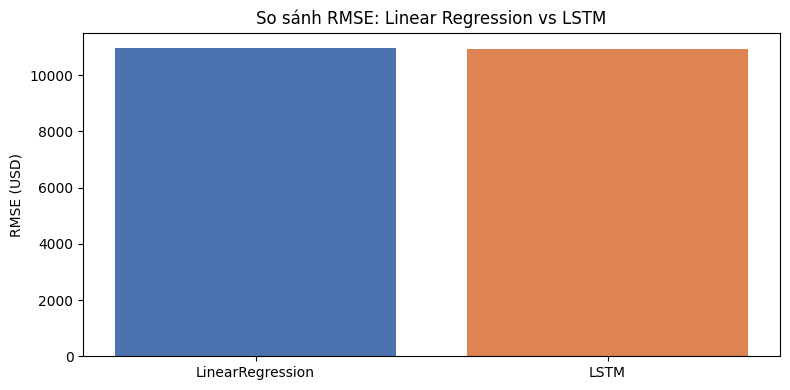

In [8]:
pred_lstm = scaler_y.inverse_transform(model.predict(X_valid_lstm)).flatten()
y_valid_inv = scaler_y.inverse_transform(y_valid_lstm.reshape(-1, 1)).flatten()

results.append(evaluate("LSTM", y_valid_inv, pred_lstm))
results_df = pd.DataFrame(results).round(3)
display(results_df)

plt.figure(figsize=(8, 4))
plt.bar(results_df["Model"], results_df["RMSE"], color=["#4C72B0", "#DD8452"])
plt.ylabel("RMSE (USD)")
plt.title("So sánh RMSE: Linear Regression vs LSTM")
plt.tight_layout(); plt.show()

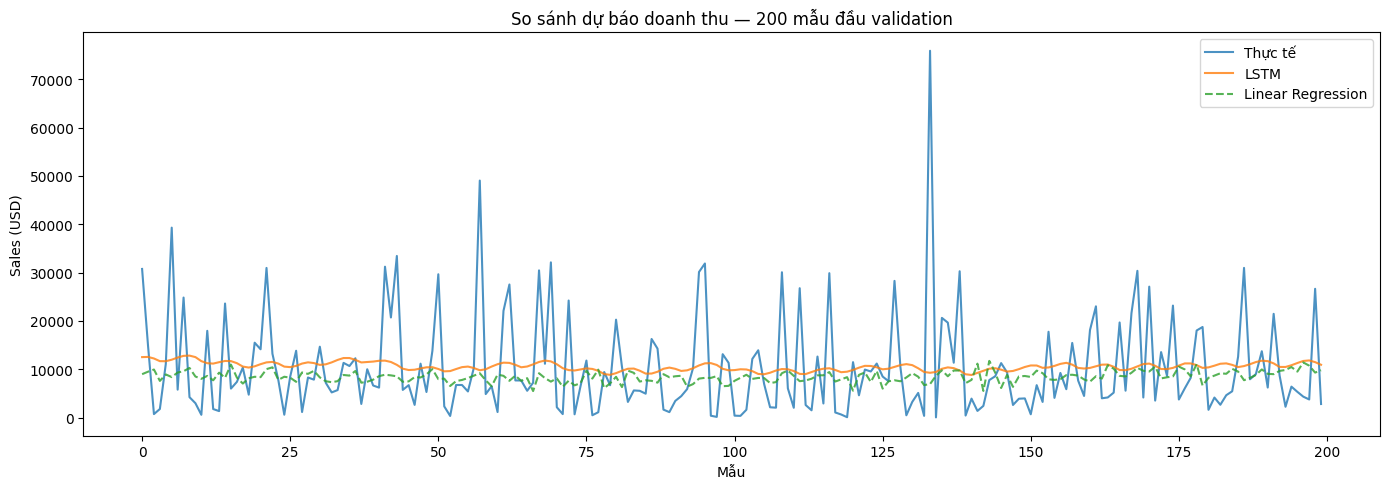

In [9]:
plt.figure(figsize=(14, 5))
plt.plot(y_valid_inv[:200], label="Thực tế", alpha=0.8)
plt.plot(pred_lstm[:200], label="LSTM", alpha=0.8)
plt.plot(pred_lr[:200], label="Linear Regression", linestyle="--", alpha=0.8)
plt.legend()
plt.title("So sánh dự báo doanh thu — 200 mẫu đầu validation")
plt.xlabel("Mẫu"); plt.ylabel("Sales (USD)")
plt.tight_layout(); plt.show()

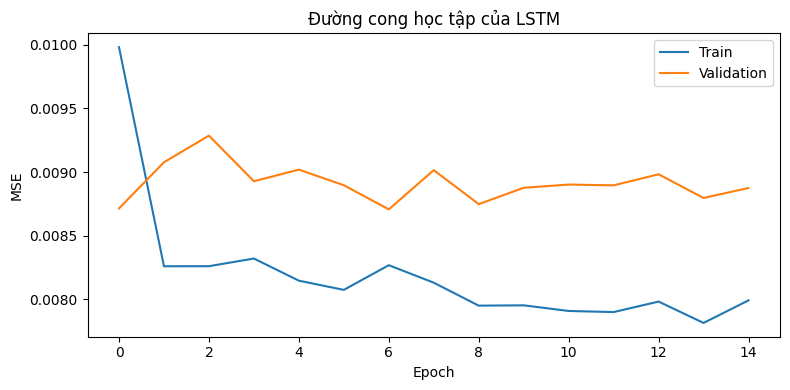

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.title("Đường cong học tập của LSTM")
plt.legend(); plt.tight_layout(); plt.show()

In [11]:
print("=" * 60)
print("KẾT QUẢ DỰ BÁO DOANH THU BÁN LẺ THEO NGÀY")
print("=" * 60)
print(results_df.to_string(index=False))
print("=" * 60)
print(f"Mô hình tốt nhất theo RMSE: {results_df.loc[results_df['RMSE'].idxmin(), 'Model']}")
results_df.to_csv("superstore_model_comparison.csv", index=False)
print("Đã lưu: superstore_model_comparison.csv")

KẾT QUẢ DỰ BÁO DOANH THU BÁN LẺ THEO NGÀY
           Model      MAE      RMSE     R2
LinearRegression 7504.169 10962.901 -0.022
            LSTM 8077.328 10923.914  0.001
Mô hình tốt nhất theo RMSE: LSTM
Đã lưu: superstore_model_comparison.csv
